In [40]:
import re
import json
import pandas as pd
from pathlib import Path

from tqdm import tqdm

In [41]:
DATA_FOLDER = Path("../data")
OUTPUT_FOLDER = Path("../outputs")

In [42]:
def fetch_candidates(df, file: str):
    # Collect all new dataframes in a fast Python list
    new_dfs = []

    for subfolder in tqdm(OUTPUT_FOLDER.iterdir()):
        # Run pattern is '001-...'
        pattern = r"^\d{3}-"
        if not re.search(pattern, subfolder.name):
            print(f"Skipping subfolder {subfolder.name} as it does not match the pattern.")
            continue
        json_file = subfolder / file
        with open(json_file, "r") as f:
            data = json.load(f)

        temp_df = pd.DataFrame(data)
        temp_df["run_name"] = subfolder.name
        new_dfs.append(temp_df)

    if new_dfs:
        return pd.concat([df] + new_dfs, ignore_index=True)

    return df


# Export Relevant Candidates

In [43]:
relevant_candidate_df = pd.DataFrame()
relevant_candidate_df = fetch_candidates(relevant_candidate_df, file="candidate_passages.json")
relevant_candidate_df = relevant_candidate_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
relevant_candidate_df.to_json(DATA_FOLDER / "relevant_candidate_passages.json", orient="records", indent=4, force_ascii=False)

43it [00:00, 431.05it/s]

Skipping subfolder agriculture-subsidies as it does not match the pattern.
Skipping subfolder free-trade-us as it does not match the pattern.
Skipping subfolder migrants-worker-criminal as it does not match the pattern.
Skipping subfolder adoption-foreign-countries as it does not match the pattern.


In [44]:
relevant_candidate_df

,run_name,corpus_id,rerank_score,speech_id,speaker_id,speaker_first_name,speaker_last_name,speaker_full_name,party,party_name,...,statutory_text_metadata,url_api_metadata,url_external_metadata,ideological_summary,statutory_text,source_url,embedding_score,evidence_rank,retrieval_query,topic
0,005-cvp-end-the-tax-and-ahv-discrimination-aga...,0.0,0.924367,196640.0,4186.0,Lisa,Mazzone,Lisa Mazzone,Grüne,Grüne Partei,...,Gestützt auf Artikel 160 Absatz 1 der Bundesve...,https://api.openparldata.ch/v1/affairs/148387,https://www.parlament.ch/de/ratsbetrieb/suche-...,In der Beratung der Revision des Bürgerrechtsg...,Gestützt auf Artikel 160 Absatz 1 der Bundesve...,,0.844405,1.0,End the tax and AHV discrimination against mar...,Civil Rights
1,005-cvp-end-the-tax-and-ahv-discrimination-aga...,10.0,0.924144,209850.0,1119.0,Jean-François,Rime,Jean-François Rime,SVP,Schweizerische Volkspartei,...,"Der Bundesrat wird beauftragt, die notwendigen...",https://api.openparldata.ch/v1/affairs/60216,https://www.parlament.ch/de/ratsbetrieb/suche-...,Am 28. Februar 2016 hat das Volk die Volksinit...,"Der Bundesrat wird beauftragt, die notwendigen...",,0.818242,2.0,End the tax and AHV discrimination against mar...,Civil Rights
2,005-cvp-end-the-tax-and-ahv-discrimination-aga...,8.0,0.884434,200894.0,3871.0,Pirmin,Bischof,Pirmin Bischof,Mitte,Die Mitte,...,"Der Bundesrat wird beauftragt, die notwendigen...",https://api.openparldata.ch/v1/affairs/60216,https://www.parlament.ch/de/ratsbetrieb/suche-...,Am 28. Februar 2016 hat das Volk die Volksinit...,"Der Bundesrat wird beauftragt, die notwendigen...",,0.819252,3.0,End the tax and AHV discrimination against mar...,Civil Rights
3,005-cvp-end-the-tax-and-ahv-discrimination-aga...,2.0,0.858970,209850.0,1119.0,Jean-François,Rime,Jean-François Rime,SVP,Schweizerische Volkspartei,...,"Der Bundesrat wird beauftragt, die notwendigen...",https://api.openparldata.ch/v1/affairs/60216,https://www.parlament.ch/de/ratsbetrieb/suche-...,Am 28. Februar 2016 hat das Volk die Volksinit...,"Der Bundesrat wird beauftragt, die notwendigen...",,0.833821,4.0,End the tax and AHV discrimination against mar...,Civil Rights
4,005-cvp-end-the-tax-and-ahv-discrimination-aga...,40.0,0.836022,157143.0,512.0,Simonetta,Sommaruga,Simonetta Sommaruga,SP,Sozialdemokratische Partei der Schweiz,...,Gestützt auf Artikel 160 Absatz 1 der Bundesve...,https://api.openparldata.ch/v1/affairs/141183,https://www.parlament.ch/de/ratsbetrieb/suche-...,1. Parallelität zwischen Unternehmenssteuerref...,Gestützt auf Artikel 160 Absatz 1 der Bundesve...,,0.800700,5.0,End the tax and AHV discrimination against mar...,Civil Rights
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,024-sp-reject-any-increase-of-deductibles-fran...,26.0,0.473891,255485.0,4193.0,Philippe,Nantermod,Philippe Nantermod,FDP-Liberale,FDP.Die Liberalen,...,Das Bundesgesetz über die Krankenversicherung ...,https://api.openparldata.ch/v1/affairs/63097,https://www.parlament.ch/de/ratsbetrieb/suche-...,Der Bundesrat hat in seiner Antwort auf die An...,Das Bundesgesetz über die Krankenversicherung ...,,0.808216,6.0,Reject any increase of deductibles (franchises).,Health
94,024-sp-reject-any-increase-of-deductibles-fran...,19.0,0.463351,255486.0,4220.0,Benjamin,Roduit,Benjamin Roduit,Mitte,Die Mitte,...,Das Bundesgesetz über die Krankenversicherung ...,https://api.openparldata.ch/v1/affairs/63097,https://www.parlament.ch/de/ratsbetrieb/suche-...,Der Bundesrat hat in seiner Antwort auf die An...,Das Bundesgesetz über die Krankenversicherung ...,,0.811771,7.0,Reject any increase of deductibles (franchises).,Health
95,024-sp-reject-any-increase-of-deductibles-fran...,10.0,0.446612,242704.0,1161.0,Alain,Berset,Alain Berset,SP,Sozialdemokratische Partei der Schweiz,...,"Der Bundesrat wird beauftragt, die ordentliche...",https://api.openparldata.ch/v1/affairs/62897,https://www.parlament.ch/de/ratsbetrieb/suche-...,Eine höhere Kostenbeteiligung schafft

# Export Non-Relevant Candidates (after deduplication)

In [67]:
non_relevant_candidate_df = pd.DataFrame()
non_relevant_candidate_df = fetch_candidates(non_relevant_candidate_df, file="candidate_passages_before_threshold.json")
non_relevant_candidate_df = non_relevant_candidate_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

43it [00:00, 144.94it/s]


Skipping subfolder agriculture-subsidies as it does not match the pattern.
Skipping subfolder free-trade-us as it does not match the pattern.
Skipping subfolder migrants-worker-criminal as it does not match the pattern.
Skipping subfolder adoption-foreign-countries as it does not match the pattern.


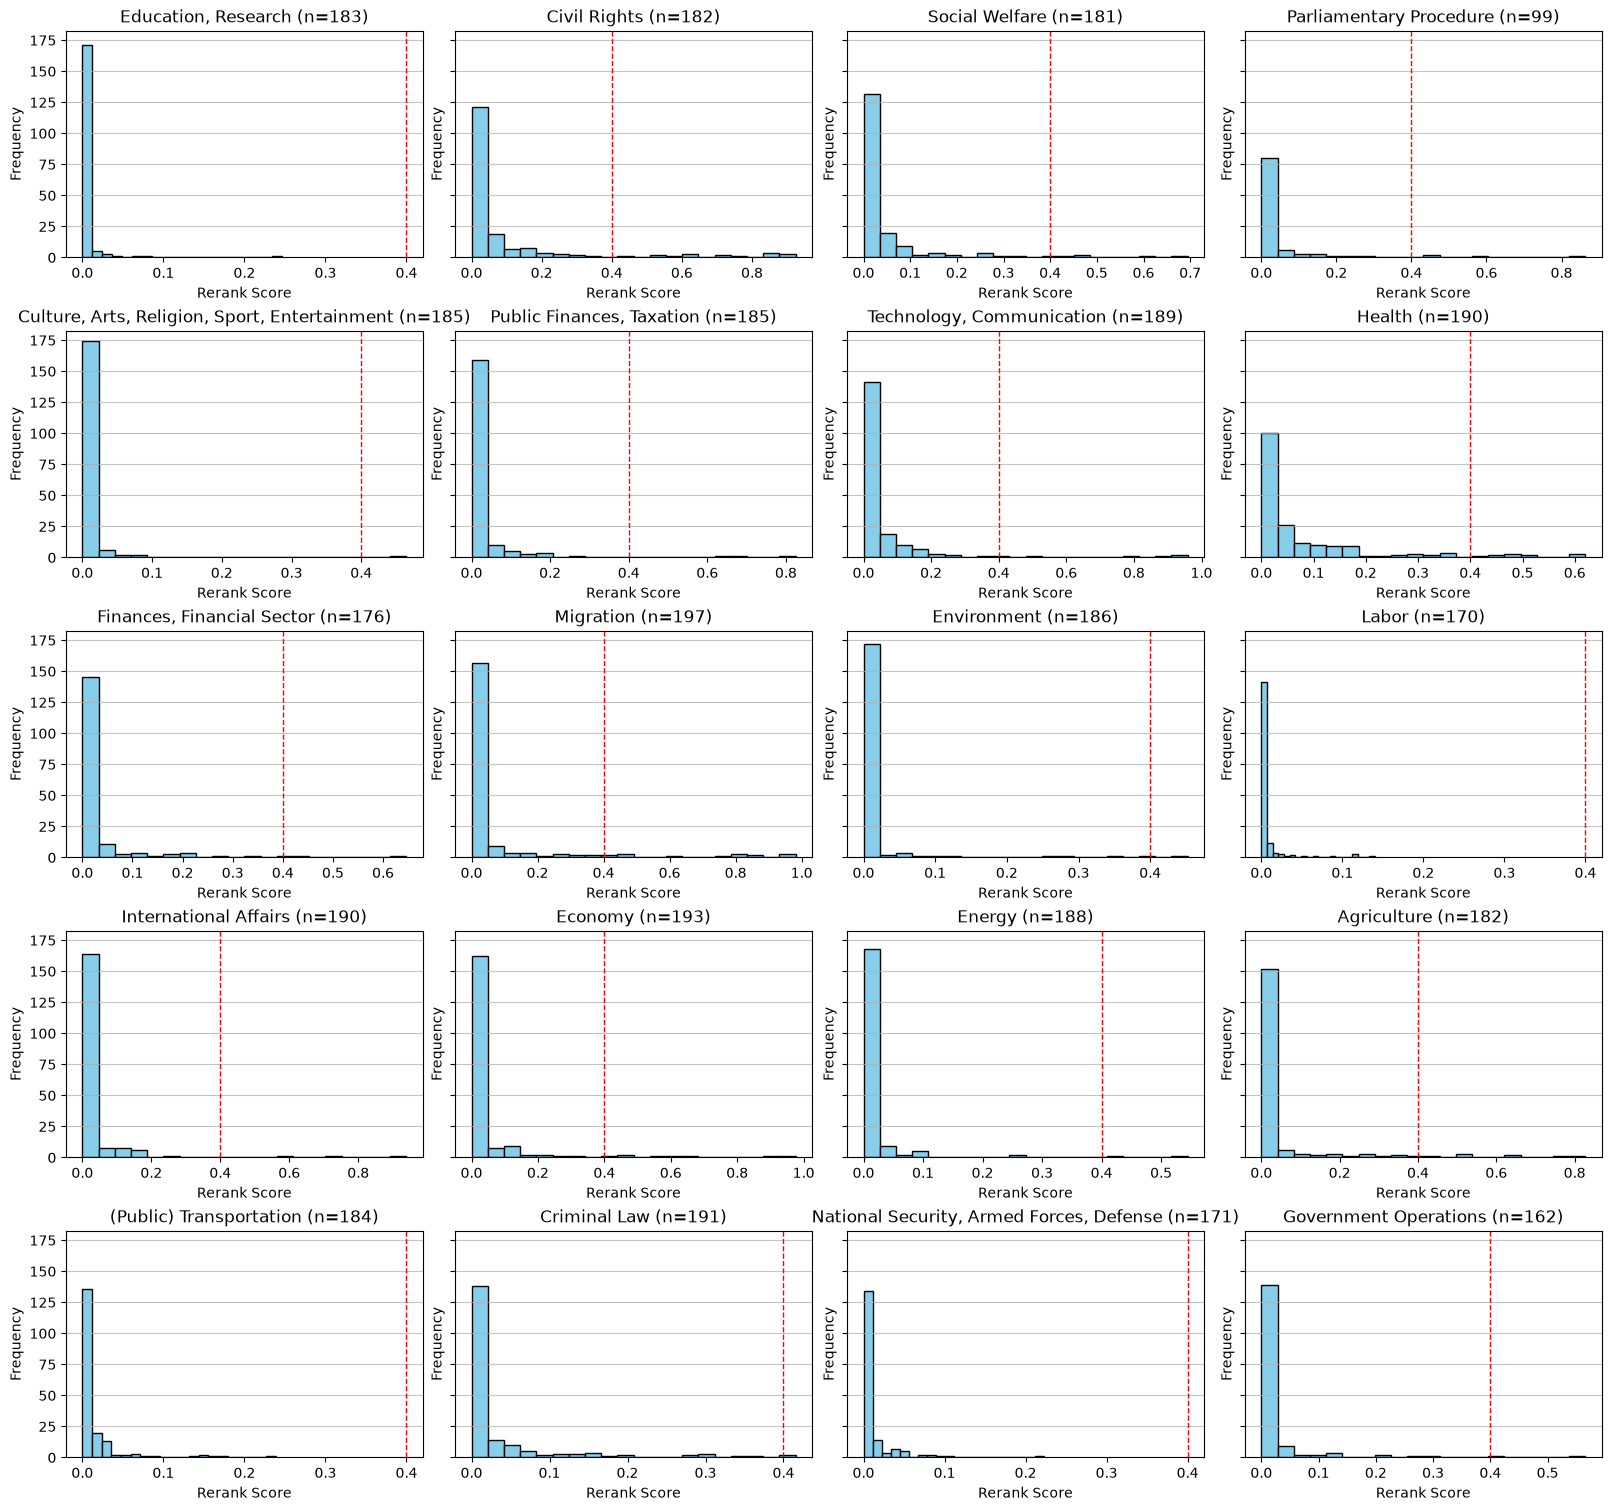

In [72]:
import matplotlib.pyplot as plt

topics = non_relevant_candidate_df["topic"].unique()
cols = 4
rows = (len(topics) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3), constrained_layout=True, sharey=True)
axes = axes.flatten()

for i, topic in enumerate(topics):
    topic_df = non_relevant_candidate_df[non_relevant_candidate_df["topic"] == topic]
    axes[i].hist(topic_df["rerank_score"].dropna(), bins=20, color='skyblue', edgecolor='black')
    axes[i].axvline(x=0.40, color='red', linestyle='dashed', linewidth=1)
    axes[i].set_title(f"{topic} (n={len(topic_df)})")
    axes[i].set_xlabel("Rerank Score")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis='y', alpha=0.75)

# hide any unused axes
for j in range(len(topics), len(axes)):
    axes[j].set_visible(False)

plt.show()

In [73]:
non_overlapping_candidate_df = non_relevant_candidate_df[~non_relevant_candidate_df["text"].isin(relevant_candidate_df["text"])].reset_index(drop=True)

### Stratified Weighted Candidates Sampling
The reranking_score is used to sample a stratified weighted dataset of candidates. The sampling is done based on the language, topic, and party of the candidates.

I expect the distribution to be very long tailed, with a few candidates having reranking scores close to the threshold while many candidates having reranking scores close to 0.

In [83]:
# Stratified sample per-language, per-topic, per-party
N_PER_GROUP = 30
stratified_weighted_df = (
    non_overlapping_candidate_df
    .groupby(["language", "topic", "party"], group_keys=False)
    .apply(
        lambda x: x.sample(n=min(N_PER_GROUP, len(x)), replace=False).assign(
            language=x.name[0],
            topic=x.name[1],
            party=x.name[2],
        )
    )
    .reset_index(drop=True)
)

print(f"Stratified sample size: {len(stratified_weighted_df)}")

Stratified sample size: 3023


In [84]:
stratified_weighted_df.columns

Index(['corpus_id', 'rerank_score', 'speech_id', 'speaker_id',
       'speaker_first_name', 'speaker_last_name', 'speaker_full_name',
       'party_name', 'gender', 'meeting_date', 'session_name', 'year',
       'debate_id', 'bill_number', 'Affair_ID', 'bill_title_de',
       'bill_title_fr', 'bill_labels', 'discussion_id', 'partition_id',
       'paragraph_id', 'speaker_name', 'speaker_role', 'text',
       'metadata_available', 'ideological_summary_metadata',
       'statutory_text_metadata', 'url_api_metadata', 'url_external_metadata',
       'ideological_summary', 'statutory_text', 'source_url',
       'embedding_score', 'evidence_rank', 'retrieval_query', 'run_name',
       'language', 'topic', 'party'],
      dtype='str')

In [85]:
stratified_weighted_df.to_json(DATA_FOLDER / "stratified_non_relevant_candidate_passages.json", orient="records", indent=4, force_ascii=False)

In [86]:
stratified_weighted_df.groupby("language").size()

language
DE    1590
FR    1322
IT     111
dtype: int64

In [87]:
stratified_weighted_df.groupby("topic").size()

topic
(Public) Transportation                          169
Agriculture                                      145
Civil Rights                                     143
Criminal Law                                     152
Culture, Arts, Religion, Sport, Entertainment    178
Economy                                          170
Education, Research                              140
Energy                                           167
Environment                                      157
Finances, Financial Sector                       138
Government Operations                            133
Health                                           140
International Affairs                            169
Labor                                            142
Migration                                        168
National Security, Armed Forces, Defense         159
Parliamentary Procedure                           87
Public Finances, Taxation                        162
Social Welfare                          

In [88]:
stratified_weighted_df.groupby("party").size()

party
BDP              15
CSP               3
CVP             418
EVP              11
FDP-Liberale    588
GLP              54
Grüne           248
LDP               1
Lega             18
MCG              11
Mitte           128
PdA              12
SP              796
SVP             684
parteilos        36
dtype: int64

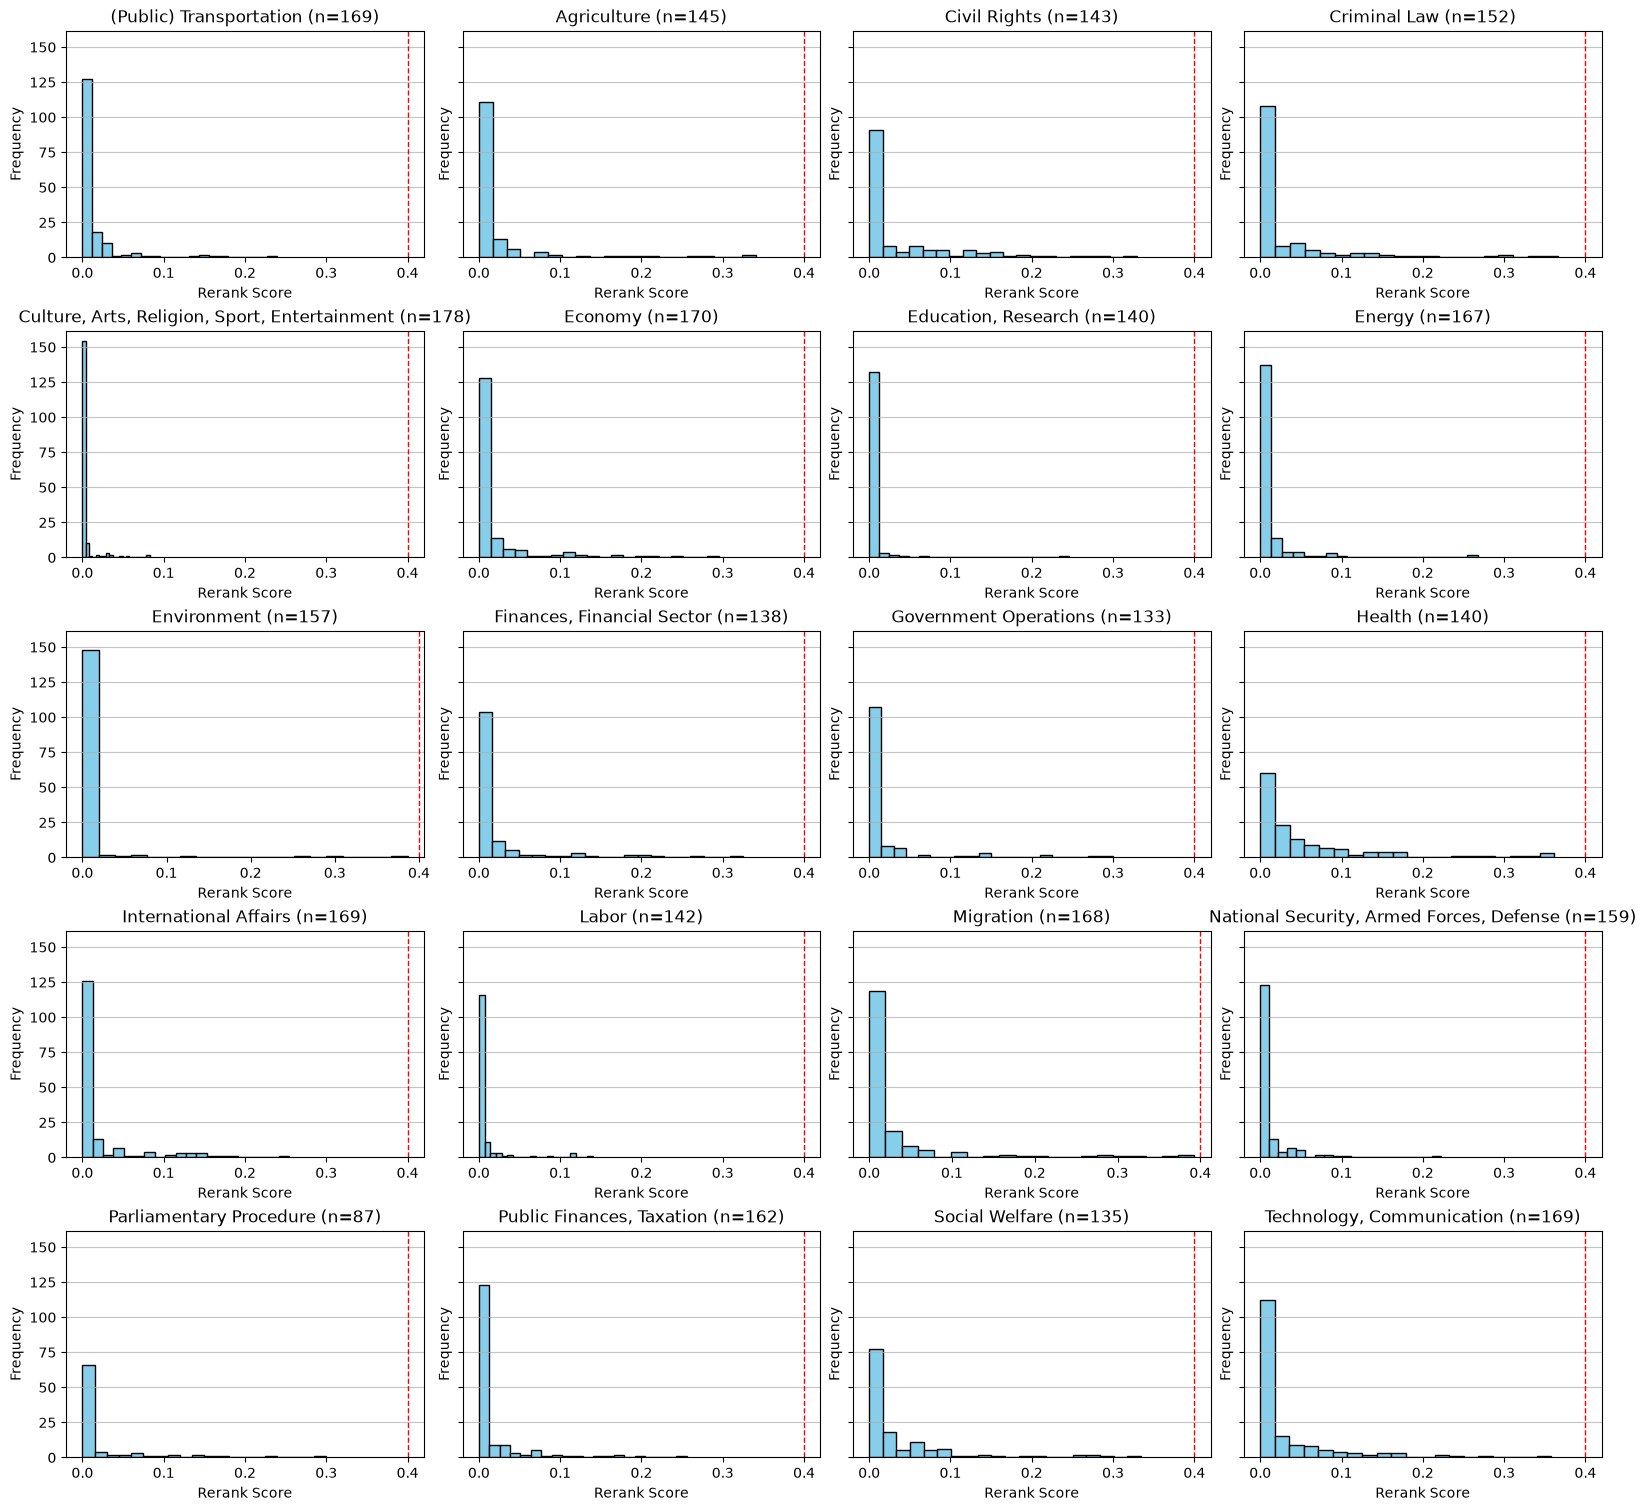

In [89]:
import matplotlib.pyplot as plt

topics = stratified_weighted_df["topic"].unique()
cols = 4
rows = (len(topics) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3), constrained_layout=True, sharey=True)
axes = axes.flatten()

for i, topic in enumerate(topics):
    topic_df = stratified_weighted_df[stratified_weighted_df["topic"] == topic]
    axes[i].hist(topic_df["rerank_score"].dropna(), bins=20, color='skyblue', edgecolor='black')
    axes[i].axvline(x=0.40, color='red', linestyle='dashed', linewidth=1)
    axes[i].set_title(f"{topic} (n={len(topic_df)})")
    axes[i].set_xlabel("Rerank Score")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis='y', alpha=0.75)

# hide any unused axes
for j in range(len(topics), len(axes)):
    axes[j].set_visible(False)

plt.show()